# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [2]:
from pathlib import Path
import pandas as pd

# Your project folder
base = Path.home() / "Documents" / "data-viz-class-material-w2026"

# Find CSV files containing CO2 or emission in their names
matches = [
    f for f in base.rglob("*.csv")
    if "co2" in f.name.lower() or "emission" in f.name.lower()
]

if matches:
    for i, file in enumerate(matches):
        print(f"{i}: {file}")

    # Load the first matching file
    df = pd.read_csv(matches[0])

    print("\nLoaded:", matches[0])
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head())

else:
    print("No CO2 CSV found. Available CSV files:")

    for file in base.rglob("*.csv"):
        print(file)

0: /Users/aiman/Documents/data-viz-class-material-w2026/data/co2_emissions.csv

Loaded: /Users/aiman/Documents/data-viz-class-material-w2026/data/co2_emissions.csv
Shape: (345, 5)
Columns: ['Country', 'Region', 'Year', 'CO2_Mt', 'CO2_per_capita']


,Country,Region,Year,CO2_Mt,CO2_per_capita
0,United States,North America,2000,5857.6,1.32
1,United States,North America,2001,5724.0,1.26
2,United States,North America,2002,5652.8,1.11
3,United States,North America,2003,5592.8,1.29
4,United States,North America,2004,5743.2,1.12


In [7]:
# Explore CO2 emissions in 2022

df_2022 = df[df["Year"] == 2022].copy()

print("Number of countries:", df_2022["Country"].nunique())

print("\nHighest CO2 emitters in 2022:")
print(
    df_2022.nlargest(5, "CO2_Mt")[["Country", "CO2_Mt"]]
    .to_string(index=False)
)

print("\nLowest CO2 emitters in 2022:")
print(
    df_2022.nsmallest(5, "CO2_Mt")[["Country", "CO2_Mt"]]
    .to_string(index=False)
)

print("\nIndia's CO2 emissions in 2022:")
print(
    df_2022.loc[
        df_2022["Country"] == "India",
        ["Country", "CO2_Mt", "CO2_per_capita"]
    ].to_string(index=False)
)

Number of countries: 15

Highest CO2 emitters in 2022:
      Country  CO2_Mt
        China 12409.5
United States  4325.9
        India  2661.1
       Russia  1323.1
    Indonesia   930.5

Lowest CO2 emitters in 2022:
       Country  CO2_Mt
United Kingdom   125.3
        France   222.5
       Germany   315.1
        Canada   461.7
     Australia   493.7

India's CO2 emissions in 2022:
Country  CO2_Mt  CO2_per_capita
  India  2661.1            3.36


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

In [10]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 7.8 MB 16.2 MB/s eta 0:00:01
     |████████████████████████████████| 2.9 MB 6.6 MB/s eta 0:00:01
     |████████████████████████████████| 4.7 MB 5.2 MB/s eta 0:00:01
     |████████████████████████████████| 126 kB 12.2 MB/s eta 0:00:01
     |████████████████████████████████| 64 kB 7.7 MB/s eta 0:00:011
     |████████████████████████████████| 249 kB 8.4 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


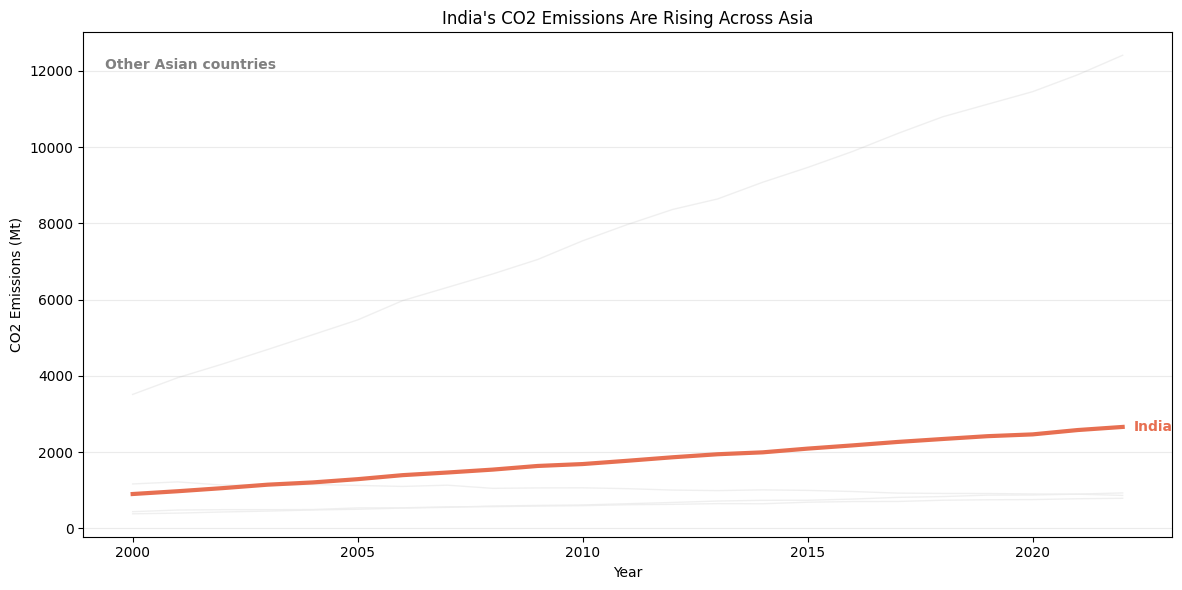

In [13]:
import matplotlib.pyplot as plt

# Select Asian countries
asia = df[df["Region"].str.contains("Asia", case=False, na=False)].copy()

# Aggregate CO2 emissions by country and year
asia = asia.groupby(
    ["Country", "Year"], as_index=False
)["CO2_Mt"].sum()

fig, ax = plt.subplots(figsize=(12, 6))

# Plot all countries, highlighting India
for country, data in asia.groupby("Country"):
    data = data.sort_values("Year")

    if country == "India":
        ax.plot(
            data["Year"],
            data["CO2_Mt"],
            color="#E76F51",
            linewidth=3,
            zorder=5
        )

        # Label India at the end of its line
        ax.annotate(
            "India",
            xy=(data["Year"].iloc[-1], data["CO2_Mt"].iloc[-1]),
            xytext=(8, 0),
            textcoords="offset points",
            color="#E76F51",
            fontweight="bold",
            va="center"
        )
    else:
        ax.plot(
            data["Year"],
            data["CO2_Mt"],
            color="#EEEEEE",
            linewidth=1,
            alpha=0.9,
            zorder=1
        )
        
        # Label the grey lines as other Asian countries
ax.text(
    0.02, 0.95,
    "Other Asian countries",
    transform=ax.transAxes,
    color="grey",
    fontsize=10,
    fontweight="bold",
    va="top"
)

ax.set_title("India's CO2 Emissions Are Rising Across Asia")
ax.set_xlabel("Year")
ax.set_ylabel("CO2 Emissions (Mt)")
ax.grid(axis="y", alpha=0.25)


plt.tight_layout()
plt.show()